# Insider Threat Detection Using Elastic Net Regularized Logistic Regression

**Course:** Machine Learning (25SC2107E)
**Team Members:** G. Eesha Yuktha (2520030436), Sai Saranya (2520030258)
**Phase:** Phase 1 — Exploratory Data Analysis (EDA)
**Dataset:** `insider_threat_dataset_1500_rows.csv` (1500 rows, 23 columns)

> **Scope note:** This notebook covers everything up to and including exploratory
> data analysis — loading, data quality checks, descriptive statistics,
> univariate/bivariate analysis, correlation study, and outlier detection.
> Feature engineering, the Elastic Net Logistic Regression model, and
> evaluation belong to the next phase and are **not** included here.

*CO1: This notebook corresponds to the first ("data") stage of the end-to-end ML lifecycle — data → features → training → evaluation → deployment → monitoring.*


## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

OUTPUT_DIR = "eda_plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Data Loading

If running on **Google Colab**, upload `insider_threat_dataset_1500_rows.csv` to the
Colab file browser (left sidebar → folder icon → upload) before running this cell,
or use the upload widget below.

In [2]:
DATA_PATH = "insider_threat_dataset_1500_rows.csv"

# Uncomment the block below if running on Google Colab and the file
# is not already present in the working directory.
# from google.colab import files
# uploaded = files.upload()
# DATA_PATH = list(uploaded.keys())[0]

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded successfully -> shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Dataset loaded successfully -> shape: 1500 rows x 23 columns


,event_id,user_id,event_date,department,role,device_type,operating_system,login_count,login_hour,failed_logins,...,external_device_usage,data_download_mb,access_frequency,unique_files_accessed,unusual_location,unusual_login,email_activity,http_activity,unusual_activity_score,insider_threat
0,EVT101117,USR1134,2026-11-15,IT,Employee,Workstation,Windows,5,9,0,...,0,103.2,8,20,0,0,14,39,0.017,0
1,EVT101369,USR1248,2026-11-26,IT,Manager,Workstation,Windows,15,21,2,...,1,277.2,28,51,0,1,28,99,0.419,1
2,EVT100423,USR1029,2026-01-02,Sales,Contractor,Workstation,Linux,5,10,1,...,0,81.8,8,20,0,0,16,43,0.035,0
3,EVT100414,USR1224,2026-09-05,Engineering,Contractor,Laptop,Windows,12,10,0,...,0,75.0,14,17,0,0,11,45,0.038,0
4,EVT100452,USR1216,2026-01-08,Operations,Contractor,Workstation,Linux,8,8,0,...,0,91.6,14,23,0,0,16,35,0.046,0


## 2. Structural Overview & Data Quality Checks

In [3]:
print("--- Column data types ---")
print(df.dtypes)


--- Column data types ---
event_id                        str
user_id                         str
event_date                      str
department                      str
role                            str
device_type                     str
operating_system                str
login_count                   int64
login_hour                    int64
failed_logins                 int64
file_access_count             int64
sensitive_files_accessed      int64
after_hours_access            int64
external_device_usage         int64
data_download_mb            float64
access_frequency              int64
unique_files_accessed         int64
unusual_location              int64
unusual_login                 int64
email_activity                int64
http_activity                 int64
unusual_activity_score      float64
insider_threat                int64
dtype: object


In [4]:
print("--- Missing values per column ---")
missing = df.isnull().sum()
print(missing)
print(f"\nTotal missing values in dataset: {missing.sum()}")


--- Missing values per column ---
event_id                    0
user_id                     0
event_date                  0
department                  0
role                        0
device_type                 0
operating_system            0
login_count                 0
login_hour                  0
failed_logins               0
file_access_count           0
sensitive_files_accessed    0
after_hours_access          0
external_device_usage       0
data_download_mb            0
access_frequency            0
unique_files_accessed       0
unusual_location            0
unusual_login               0
email_activity              0
http_activity               0
unusual_activity_score      0
insider_threat              0
dtype: int64

Total missing values in dataset: 0


In [5]:
print("--- Duplicate rows ---")
dup_count = df.duplicated().sum()
print(f"Duplicate rows found: {dup_count}")

print("\n--- Unique identifiers ---")
print(f"Unique event_id count : {df['event_id'].nunique()} (should equal row count: {len(df)})")
print(f"Unique user_id count  : {df['user_id'].nunique()}")


--- Duplicate rows ---
Duplicate rows found: 0

--- Unique identifiers ---
Unique event_id count : 1500 (should equal row count: 1500)
Unique user_id count  : 250


## 3. Descriptive Statistics

In [6]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
categorical_cols = [c for c in categorical_cols if c not in ("event_id", "user_id", "event_date")]

print(f"Numerical features ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")


Numerical features (16): ['login_count', 'login_hour', 'failed_logins', 'file_access_count', 'sensitive_files_accessed', 'after_hours_access', 'external_device_usage', 'data_download_mb', 'access_frequency', 'unique_files_accessed', 'unusual_location', 'unusual_login', 'email_activity', 'http_activity', 'unusual_activity_score', 'insider_threat']
Categorical features (4): ['department', 'role', 'device_type', 'operating_system']


In [7]:
df[numeric_cols].describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
login_count,1500.0,8.490,4.288,1.0,6.000,8.000,10.000,27.00
login_hour,1500.0,10.734,3.739,0.0,9.000,11.000,12.000,23.00
failed_logins,1500.0,1.027,1.422,0.0,0.000,1.000,1.000,12.00
file_access_count,1500.0,37.255,19.825,12.0,25.000,29.000,36.000,99.00
sensitive_files_accessed,1500.0,4.122,4.516,0.0,1.000,2.000,5.000,27.00
after_hours_access,1500.0,0.168,0.374,0.0,0.000,0.000,0.000,1.00
external_device_usage,1500.0,0.166,0.372,0.0,0.000,0.000,0.000,1.00
data_download_mb,1500.0,218.506,348.104,10.0,55.225,86.050,164.475,3046.20
access_frequency,1500.0,13.621,8.316,1.0,8.000,11.000,15.000,43.00
unique_files_accessed,1500.0,25.391,15.728,6.0,16.000,19.000,25.000,74.00


In [8]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())



department:
department
Engineering    317
IT             271
Operations     249
Sales          240
Finance        179
HR             124
Legal          120
Name: count, dtype: int64

role:
role
Employee         822
Analyst          234
Manager          191
Contractor       174
Administrator     79
Name: count, dtype: int64

device_type:
device_type
Laptop             751
Desktop            317
Workstation        298
Virtual Machine    134
Name: count, dtype: int64

operating_system:
operating_system
Windows    1026
Linux       316
macOS       158
Name: count, dtype: int64


## 4. Target Variable Analysis (Class Imbalance Check)

In [9]:
counts = df["insider_threat"].value_counts()
pct = df["insider_threat"].value_counts(normalize=True) * 100
for cls in counts.index:
    label = "Threat" if cls == 1 else "Normal"
    print(f"Class {cls} ({label}): {counts[cls]} records ({pct[cls]:.2f}%)")

imbalance_ratio = counts[0] / counts[1]
print(f"\nImbalance ratio (Normal:Threat) = {imbalance_ratio:.2f} : 1")
print("Note: This class imbalance will need to be addressed via class_weight,")
print("      resampling, or threshold tuning in the model-training phase.")


Class 0 (Normal): 1200 records (80.00%)
Class 1 (Threat): 300 records (20.00%)

Imbalance ratio (Normal:Threat) = 4.00 : 1
Note: This class imbalance will need to be addressed via class_weight,
      resampling, or threshold tuning in the model-training phase.


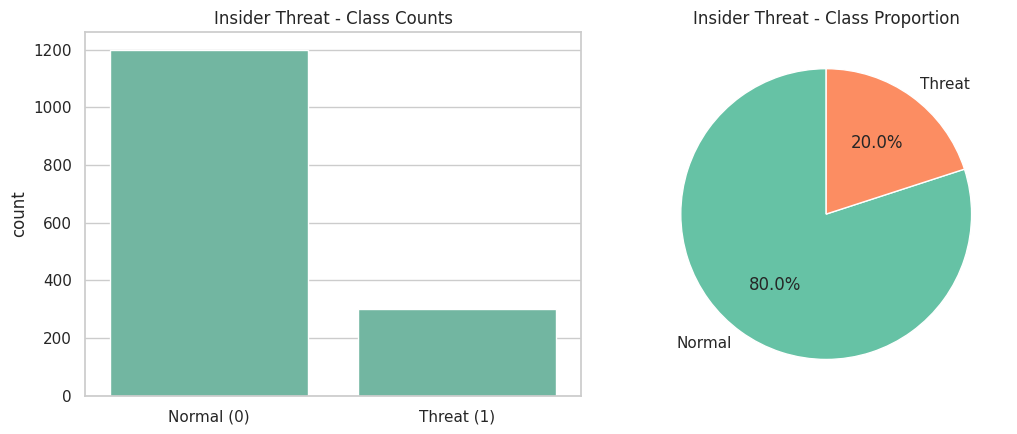

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.countplot(x="insider_threat", data=df, ax=ax[0])
ax[0].set_title("Insider Threat - Class Counts")
ax[0].set_xticklabels(["Normal (0)", "Threat (1)"])
ax[0].set_xlabel("")

ax[1].pie(counts, labels=["Normal", "Threat"], autopct="%1.1f%%",
          startangle=90, colors=sns.color_palette("Set2"))
ax[1].set_title("Insider Threat - Class Proportion")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/01_target_distribution.png")
plt.show()


## 5. Univariate Analysis — Numerical Features

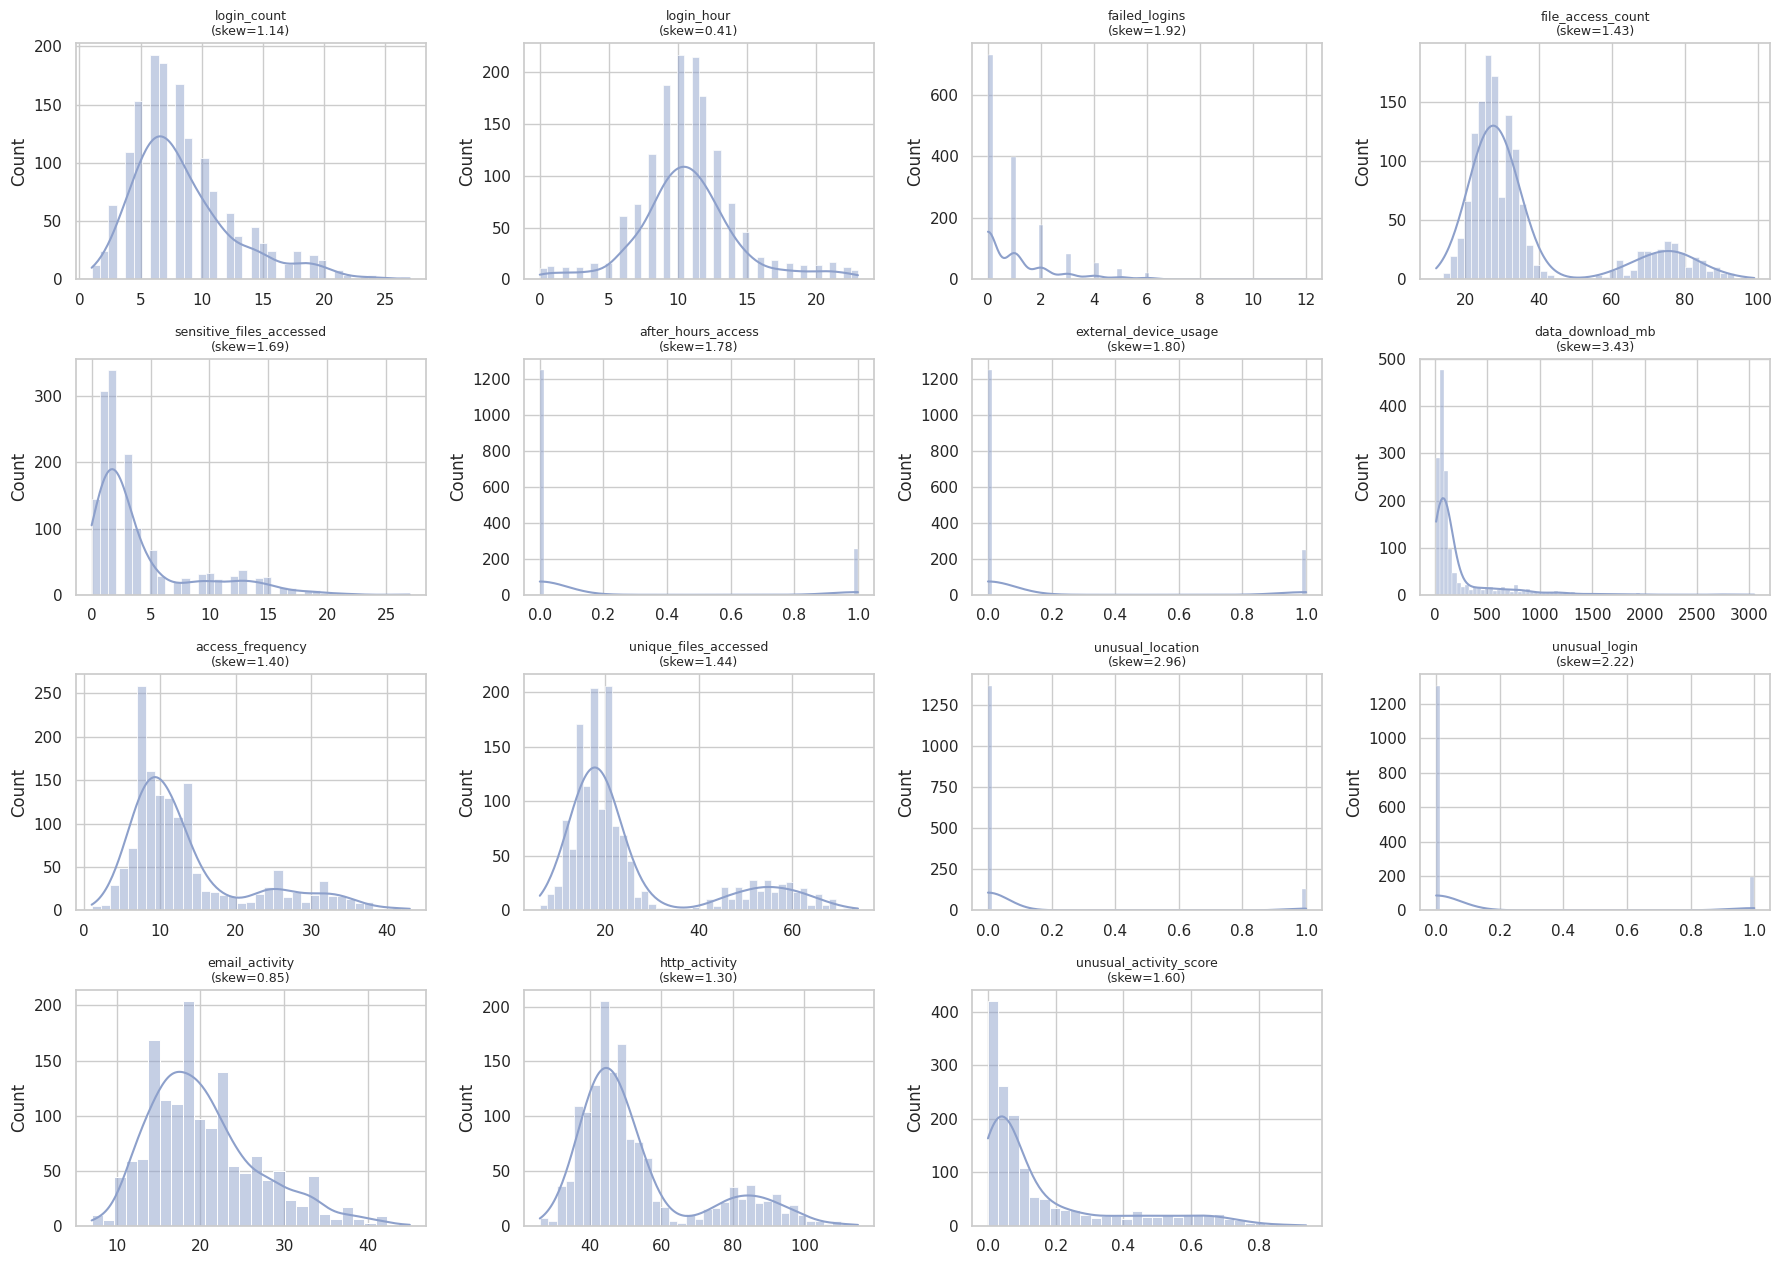

In [11]:
plot_cols = [c for c in numeric_cols if c != "insider_threat"]
n_cols = 4
n_rows = int(np.ceil(len(plot_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color=sns.color_palette("Set2")[2])
    skew_val = df[col].skew()
    axes[i].set_title(f"{col}\n(skew={skew_val:.2f})", fontsize=9)
    axes[i].set_xlabel("")

for j in range(len(plot_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_numerical_distributions.png")
plt.show()


In [12]:
print("--- Skewness of numerical features ---")
df[plot_cols].skew().sort_values(ascending=False).round(3)


--- Skewness of numerical features ---


data_download_mb            3.428
unusual_location            2.956
unusual_login               2.220
failed_logins               1.925
external_device_usage       1.797
after_hours_access          1.778
sensitive_files_accessed    1.687
unusual_activity_score      1.601
unique_files_accessed       1.439
file_access_count           1.429
access_frequency            1.396
http_activity               1.299
login_count                 1.137
email_activity              0.851
login_hour                  0.413
dtype: float64

## 6. Univariate Analysis — Categorical Features

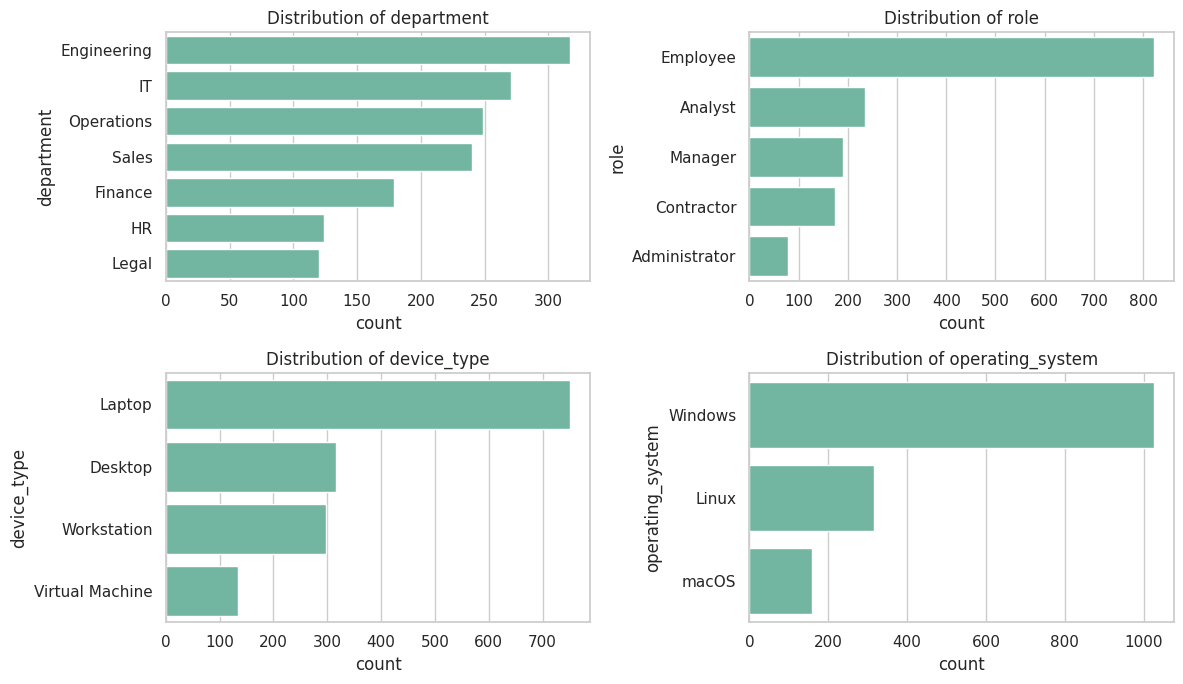

In [13]:
n_cols = 2
n_rows = int(np.ceil(len(categorical_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_categorical_distributions.png")
plt.show()


## 7. Bivariate Analysis — Features vs Insider Threat

In [14]:
key_features = [
    "sensitive_files_accessed", "after_hours_access", "external_device_usage",
    "data_download_mb", "unusual_location", "unusual_login",
    "failed_logins", "unusual_activity_score",
]
key_features = [f for f in key_features if f in numeric_cols]

grouped = df.groupby("insider_threat")[key_features].mean().T
grouped.columns = ["Normal (0)", "Threat (1)"]
grouped.round(3)


,Normal (0),Threat (1)
sensitive_files_accessed,2.132,12.083
after_hours_access,0.050,0.640
external_device_usage,0.068,0.557
data_download_mb,82.971,760.647
unusual_location,0.027,0.323
unusual_login,0.039,0.487
failed_logins,0.512,3.083
unusual_activity_score,0.069,0.527


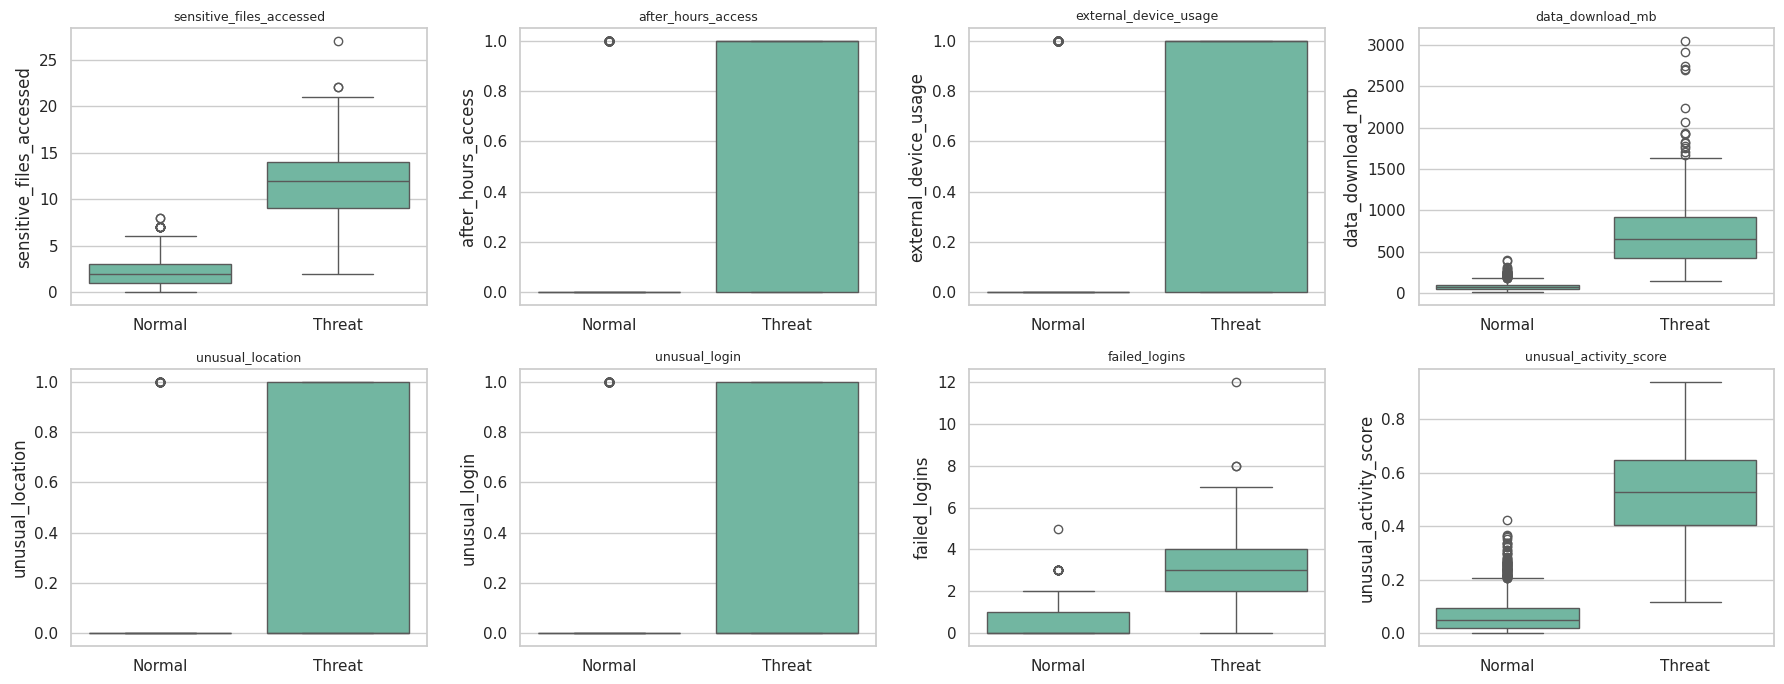

In [15]:
n_cols = 4
n_rows = int(np.ceil(len(key_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.boxplot(x="insider_threat", y=col, data=df, ax=axes[i])
    axes[i].set_xticklabels(["Normal", "Threat"])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("")

for j in range(len(key_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_bivariate_boxplots.png")
plt.show()


In [16]:
dept_rate = (df.groupby("department")["insider_threat"].mean() * 100).sort_values(ascending=False)
role_rate = (df.groupby("role")["insider_threat"].mean() * 100).sort_values(ascending=False)

print("--- Threat rate (%) by department ---")
print(dept_rate.round(2))
print("\n--- Threat rate (%) by role ---")
print(role_rate.round(2))


--- Threat rate (%) by department ---
department
Sales          25.00
Legal          23.33
Engineering    21.77
Finance        19.55
Operations     18.47
IT             16.24
HR             14.52
Name: insider_threat, dtype: float64

--- Threat rate (%) by role ---
role
Administrator    24.05
Manager          21.47
Analyst          21.37
Employee         19.46
Contractor       17.24
Name: insider_threat, dtype: float64


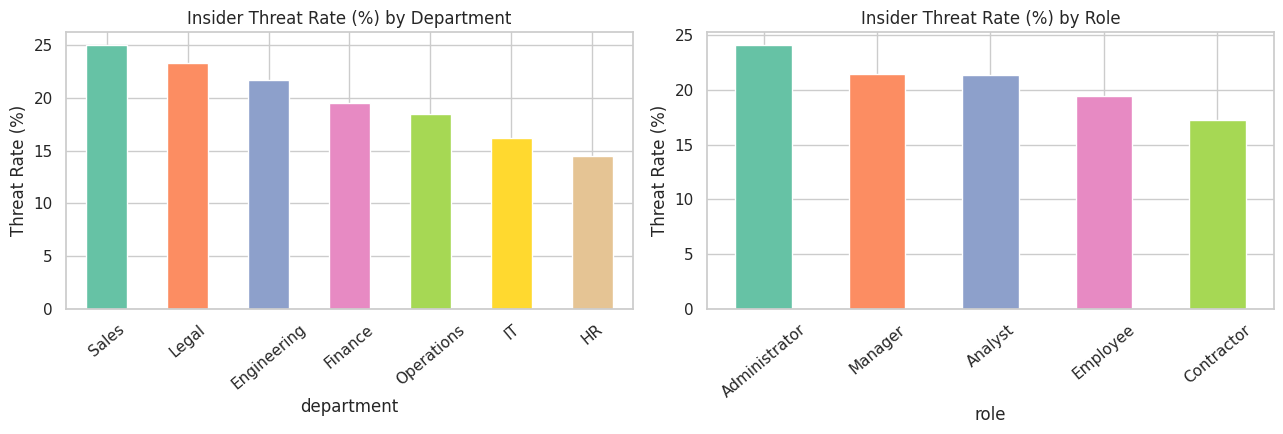

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dept_rate.plot(kind="bar", ax=ax[0], color=sns.color_palette("Set2"))
ax[0].set_title("Insider Threat Rate (%) by Department")
ax[0].set_ylabel("Threat Rate (%)")
ax[0].tick_params(axis="x", rotation=40)

role_rate.plot(kind="bar", ax=ax[1], color=sns.color_palette("Set2"))
ax[1].set_title("Insider Threat Rate (%) by Role")
ax[1].set_ylabel("Threat Rate (%)")
ax[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_threat_rate_by_group.png")
plt.show()


## 8. Correlation Analysis

*CO3 preview: correlated numerical features are exactly what Elastic Net's combined
L1/L2 penalty (planned for the next phase) is designed to handle.*

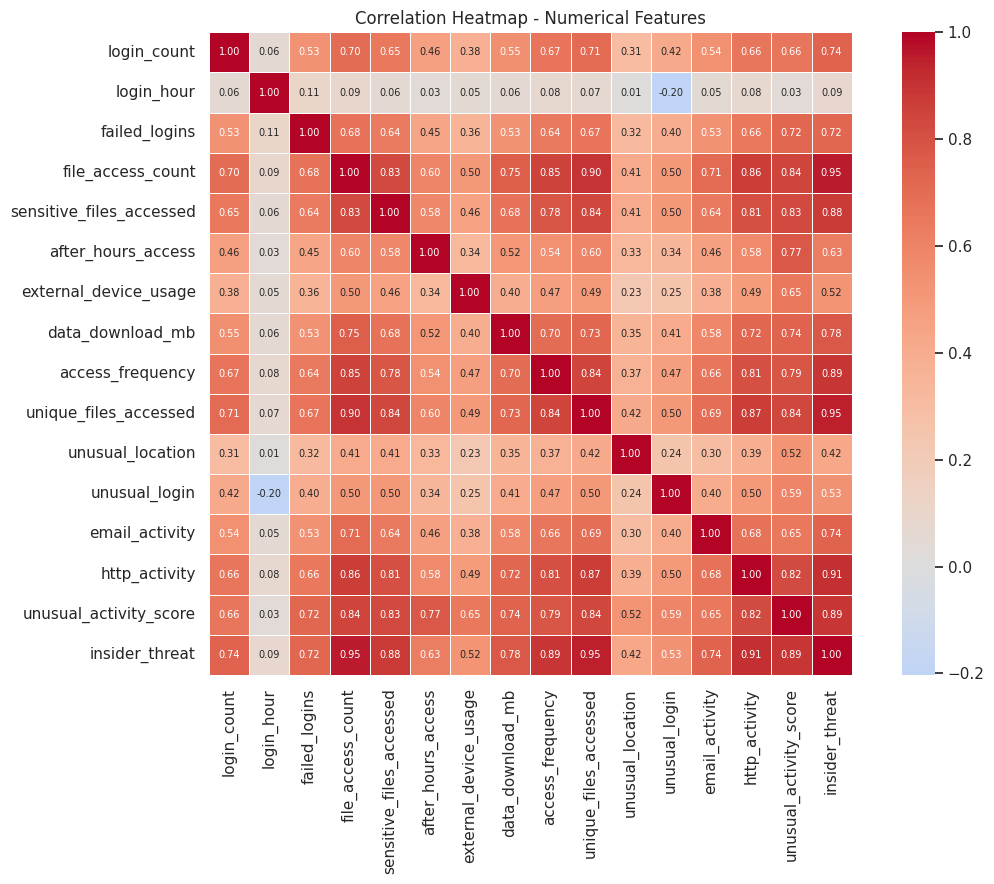

In [18]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.4, annot_kws={"size": 7})
plt.title("Correlation Heatmap - Numerical Features")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_correlation_heatmap.png")
plt.show()


In [19]:
print("--- Features most correlated with insider_threat ---")
target_corr = corr["insider_threat"].drop("insider_threat").sort_values(key=abs, ascending=False)
print(target_corr.round(3))


--- Features most correlated with insider_threat ---
file_access_count           0.954
unique_files_accessed       0.946
http_activity               0.908
unusual_activity_score      0.889
access_frequency            0.889
sensitive_files_accessed    0.882
data_download_mb            0.779
email_activity              0.736
login_count                 0.736
failed_logins               0.723
after_hours_access          0.631
unusual_login               0.535
external_device_usage       0.525
unusual_location            0.423
login_hour                  0.086
Name: insider_threat, dtype: float64


In [20]:
print("--- Highly correlated feature pairs (|r| > 0.7, excluding target) ---")
pairs_found = False
cols = [c for c in numeric_cols if c != "insider_threat"]
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.loc[cols[i], cols[j]]
        if abs(r) > 0.7:
            print(f"  {cols[i]} <-> {cols[j]} : r = {r:.3f}")
            pairs_found = True
if not pairs_found:
    print("  None found above threshold 0.7.")


--- Highly correlated feature pairs (|r| > 0.7, excluding target) ---
  login_count <-> unique_files_accessed : r = 0.706
  failed_logins <-> unusual_activity_score : r = 0.723
  file_access_count <-> sensitive_files_accessed : r = 0.832
  file_access_count <-> data_download_mb : r = 0.747
  file_access_count <-> access_frequency : r = 0.852
  file_access_count <-> unique_files_accessed : r = 0.904
  file_access_count <-> email_activity : r = 0.707
  file_access_count <-> http_activity : r = 0.865
  file_access_count <-> unusual_activity_score : r = 0.844
  sensitive_files_accessed <-> access_frequency : r = 0.781
  sensitive_files_accessed <-> unique_files_accessed : r = 0.839
  sensitive_files_accessed <-> http_activity : r = 0.811
  sensitive_files_accessed <-> unusual_activity_score : r = 0.832
  after_hours_access <-> unusual_activity_score : r = 0.773
  data_download_mb <-> unique_files_accessed : r = 0.727
  data_download_mb <-> http_activity : r = 0.725
  data_download_mb <-> u

## 9. Outlier Detection (IQR Method)

In [21]:
outlier_summary = {}
for col in plot_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = df[(df[col] < lower) | (df[col] > upper)].shape[0]
    outlier_summary[col] = n_outliers

summary_series = pd.Series(outlier_summary).sort_values(ascending=False)
print("Outlier count per feature (IQR rule):")
print(summary_series)


Outlier count per feature (IQR rule):
file_access_count           300
unique_files_accessed       298
data_download_mb            262
after_hours_access          252
external_device_usage       249
http_activity               239
access_frequency            196
failed_logins               195
unusual_login               193
unusual_activity_score      188
login_hour                  165
sensitive_files_accessed    164
unusual_location            129
login_count                  96
email_activity               37
dtype: int64


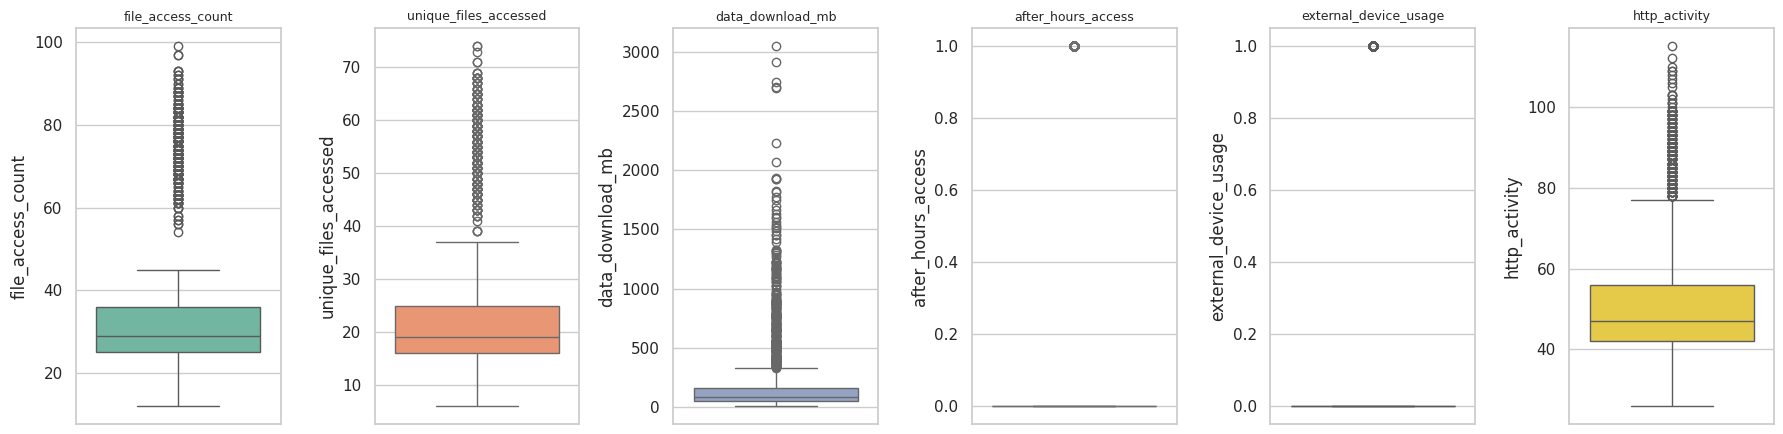

Note: Outliers here are retained for now since they likely represent
      genuine anomalous behavior relevant to insider threat detection,
      rather than data entry errors. This will be reassessed with
      domain judgement in the feature engineering phase.


In [22]:
top_features = summary_series.head(6).index.tolist()
fig, axes = plt.subplots(1, len(top_features), figsize=(3 * len(top_features), 4.5))
for i, col in enumerate(top_features):
    sns.boxplot(y=df[col], ax=axes[i], color=sns.color_palette("Set2")[i % 8])
    axes[i].set_title(col, fontsize=9)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_outlier_boxplots.png")
plt.show()

print("Note: Outliers here are retained for now since they likely represent")
print("      genuine anomalous behavior relevant to insider threat detection,")
print("      rather than data entry errors. This will be reassessed with")
print("      domain judgement in the feature engineering phase.")


## 10. Key EDA Findings

In [23]:
imbalance_ratio = counts[0] / counts[1]

findings = [
    f"Dataset has {df.shape[0]} records, {df.shape[1]} columns, no missing values, "
    f"and {df.duplicated().sum()} duplicate rows.",
    f"Target class is imbalanced ({imbalance_ratio:.1f}:1, Normal:Threat) - will require "
    f"class-weighting or resampling before model training.",
    "sensitive_files_accessed, data_download_mb, after_hours_access, unusual_location and "
    "unusual_login show visibly higher means for the Threat class in the bivariate boxplots.",
    "Several numerical features are right-skewed (e.g. data_download_mb), suggesting scaling "
    "or transformation before feeding them into a regularized logistic regression model.",
    "unusual_activity_score correlates strongly with several raw behavioral features, "
    "consistent with it being an engineered composite indicator.",
    "Threat rate varies noticeably by department and role, suggesting these categorical "
    "fields carry predictive signal and should be one-hot encoded rather than dropped.",
]

for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

print("\nNext phase (not covered in this notebook): feature engineering & encoding, "
      "train/test split, Elastic Net Logistic Regression training, and evaluation "
      "using accuracy, precision, recall, F1-score and ROC-AUC.")


1. Dataset has 1500 records, 23 columns, no missing values, and 0 duplicate rows.
2. Target class is imbalanced (4.0:1, Normal:Threat) - will require class-weighting or resampling before model training.
3. sensitive_files_accessed, data_download_mb, after_hours_access, unusual_location and unusual_login show visibly higher means for the Threat class in the bivariate boxplots.
4. Several numerical features are right-skewed (e.g. data_download_mb), suggesting scaling or transformation before feeding them into a regularized logistic regression model.
5. unusual_activity_score correlates strongly with several raw behavioral features, consistent with it being an engineered composite indicator.
6. Threat rate varies noticeably by department and role, suggesting these categorical fields carry predictive signal and should be one-hot encoded rather than dropped.

Next phase (not covered in this notebook): feature engineering & encoding, train/test split, Elastic Net Logistic Regression training